# Red de Clasificacion con Redes Neuronales Tensorflow

NOTA: Esta red de clasificacion usa el dataset de mnist de Tensorflow
#-https://www.tensorflow.org/datasets/catalog/mnist?hl=es
para identificar numeros escritos a mano.  El propio set ya viene separado con sets de entrenamiento y de pruebas

# 1.Importamos tensorflow y descargamos el set de datos

In [1]:
# 1. Import tenserflow
import tensorflow as tf
import tensorflow_datasets as tfds


2024-06-01 16:10:46.443403: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-06-01 16:10:48.196575: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [106]:
# 1.1 Descargamos el set de datos
datos, metadatos = tfds.load("mnist", # Nombre del set de datos
                              as_supervised=True, #
                              with_info=True # Descarga datos mas utiles
                            )

In [54]:
# 1.2 Visualizamos los metadatos del Set
metadatos

tfds.core.DatasetInfo(
    name='mnist',
    full_name='mnist/3.0.1',
    description="""
    The MNIST database of handwritten digits.
    """,
    homepage='http://yann.lecun.com/exdb/mnist/',
    data_dir='/root/tensorflow_datasets/mnist/3.0.1',
    file_format=tfrecord,
    download_size=11.06 MiB,
    dataset_size=21.00 MiB,
    features=FeaturesDict({
        'image': Image(shape=(28, 28, 1), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    splits={
        'test': <SplitInfo num_examples=10000, num_shards=1>,
        'train': <SplitInfo num_examples=60000, num_shards=1>,
    },
    citation="""@article{lecun2010mnist,
      title={MNIST handwritten digit database},
      author={LeCun, Yann and Cortes, Corinna and Burges, CJ},
      journal={ATT Labs [Online]. Available: http://yann.lecun.com/exdb/mnist},
      volume={2},
      year={2010}
    }""",
)

# 2. Separamos datos de entrenamiento y pruebas



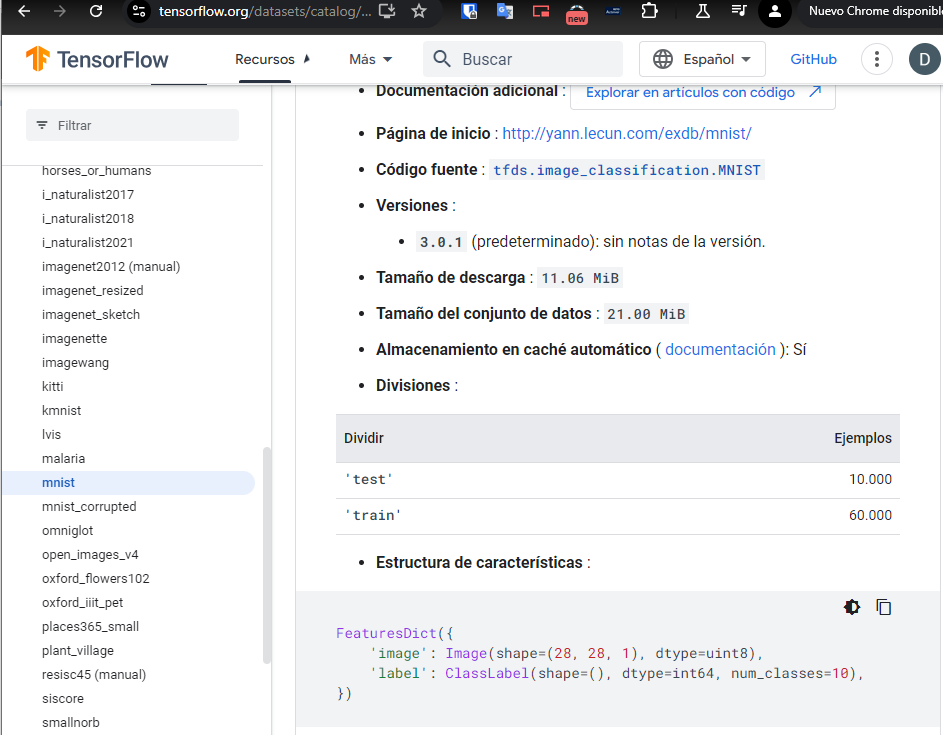

In [107]:
# 2.1 Datos de entrenamiento y pruebas
datos_entrenamiento = datos["train"]
datos_pruebas = datos["test"]
# NOTA: estos 2 valores de campos los traemos del sitio web Divisiones:
# https://www.tensorflow.org/datasets/catalog/mnist?hl=es

# Mostrar el modelo
img = Image.open('Test&Train.png')
img.show()

In [95]:
# 2.2 Visualizamos los nombres de las etiquetas
nombres_clases = metadatos.features["label"].names

# 3. Normalizamos los datos y agregamos en Cache

In [108]:
# 3.1 NOrmalizamos los datos de color 0-255 
# transformamos para en lugar de ser 0-255 sea de 0-1 
# Lo normalizamos con una funcion 

def normalizar(imagenes,etiquetas):
    imagenes = tf.cast(imagenes,tf.float32)
    imagenes = imagenes/255
    return imagenes,etiquetas

datos_entrenamiento = datos_entrenamiento.map(normalizar)
datos_pruebas = datos_pruebas.map(normalizar)
# NOTA: Usando map nos aseguramos de que por cada dato de datos_entrenamiento o datos_prueba
# Sea converido

# 3.2 Agregamos en cache los datos para que sea mas rapido
datos_entrenamiento = datos_entrenamiento.cache()
datos_pruebas = datos_pruebas.cache()


2024-06-01 17:16:57.488101: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2024-06-01 17:16:57.488737: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


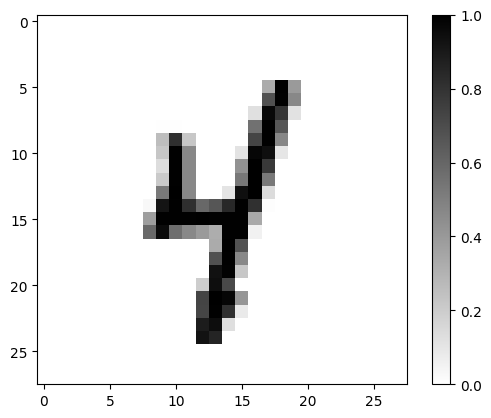

In [109]:
# 3.2 Visualizamos la informacion que trae
for imagen,etiqueta in datos_entrenamiento.take(1):
    break

# 3.3 Lo mostramos en pantall
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(imagen,cmap = plt.cm.binary)
plt.colorbar()
plt.show()

2024-06-01 17:09:14.849778: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2024-06-01 17:09:14.850028: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2024-06-01 17:09:14.877693: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence

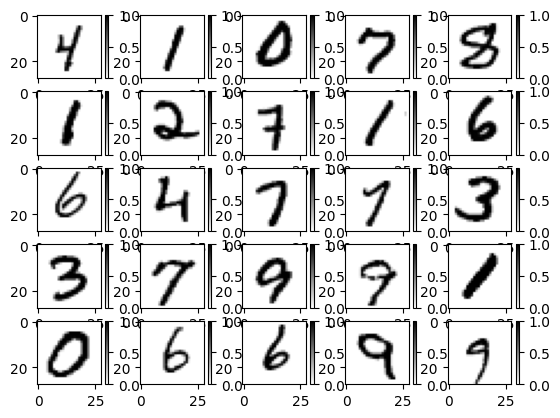

In [98]:
import matplotlib.pyplot as plt

# 3.4 Visualizamos mas muestras en pantalla usando subplots
for indice, (imagen,etiqueta ) in enumerate(datos_entrenamiento.take(25)):
    # 3.3 Lo mostramos en pantall
    plt.subplot(5,5,indice + 1)
    plt.imshow(imagen,cmap = plt.cm.binary)
    plt.colorbar()
plt.show()

# 4. Creamos nuestro modelo

In [110]:
# 4.1 Creamos el modelo de  nuestra red neronal
modelo = tf.keras.Sequential(
    [
        # Convertimos todos los datos "pixeles" en un vector de 
        tf.keras.layers.Flatten(input_shape=(28,28,1)), # 1 = blanco y negro 
        # Especificamos todas las capas de la red neuronal que queremos
        # al perceptron o multicapa
        
            # # #  1 CAPA OCULTA - CON 1 NEURONA
            #tf.keras.layers.Dense(1), # Lo dejamos con 1 capa con 1 sola neurona
            
            # # #  2 CAPAS OCULTAS - CON 50 NEURONAS CADA UNA
            #tf.keras.layers.Dense(50), # Lo dejamos con 1 capa con 50  neuronas
            #tf.keras.layers.Dense(50), # Lo dejamos con 2 capa con 50  neuronas

            # # #  2 CAPAS OCULTAS - CON 50 NEURONAS CADA UNA y CON FUNCION DE ACTIVACION RELU
            # # #  USAMOS RELU par anumero negativos da 0 y + da ese mismo numero
            tf.keras.layers.Dense(50, activation=tf.nn.relu), # Lo dejamos con 1 capa con 50  neuronas
            tf.keras.layers.Dense(50, activation=tf.nn.relu), # Lo dejamos con 2 capa con 50  neuronas

        # Agregamos la capa de salida 
        # # # CAPA DE SALIDA con 10 que son los 10 numeros.
        tf.keras.layers.Dense(10,activation=tf.nn.softmax)
        
    ]
)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


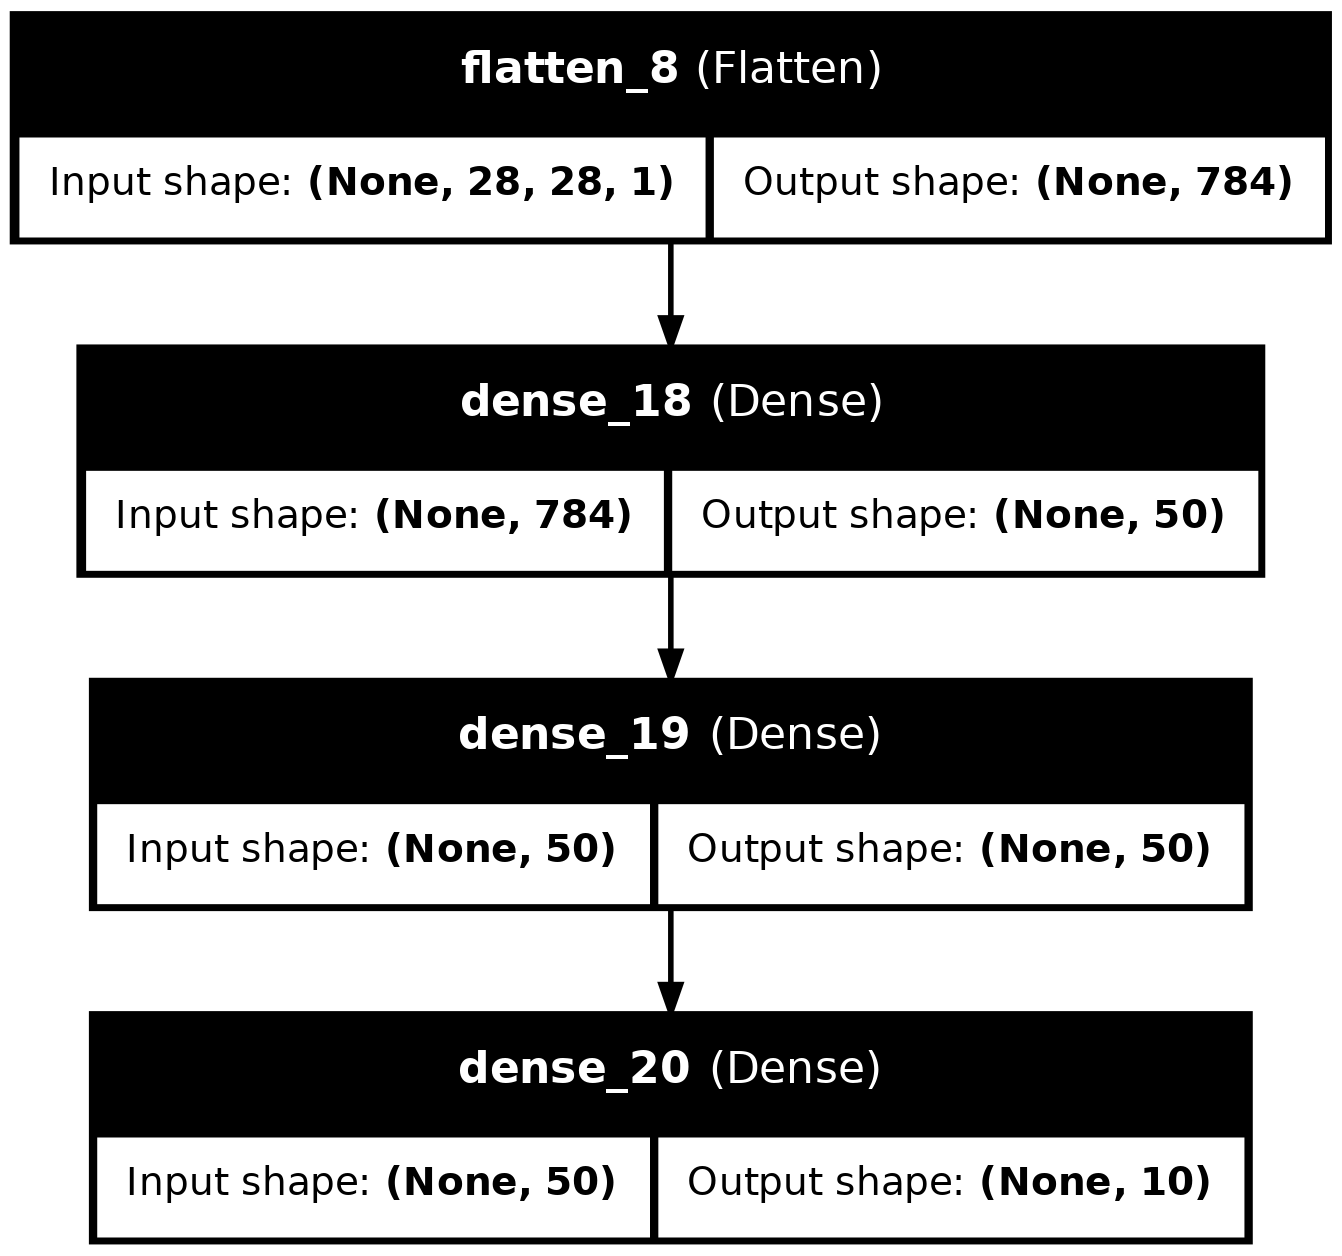

In [100]:
# 4.2 Visualizamos nuestro modelo neuronal de forma simple
from keras.utils import plot_model
plot_model(modelo, to_file='modelo.png', show_shapes=True, show_layer_names=True)

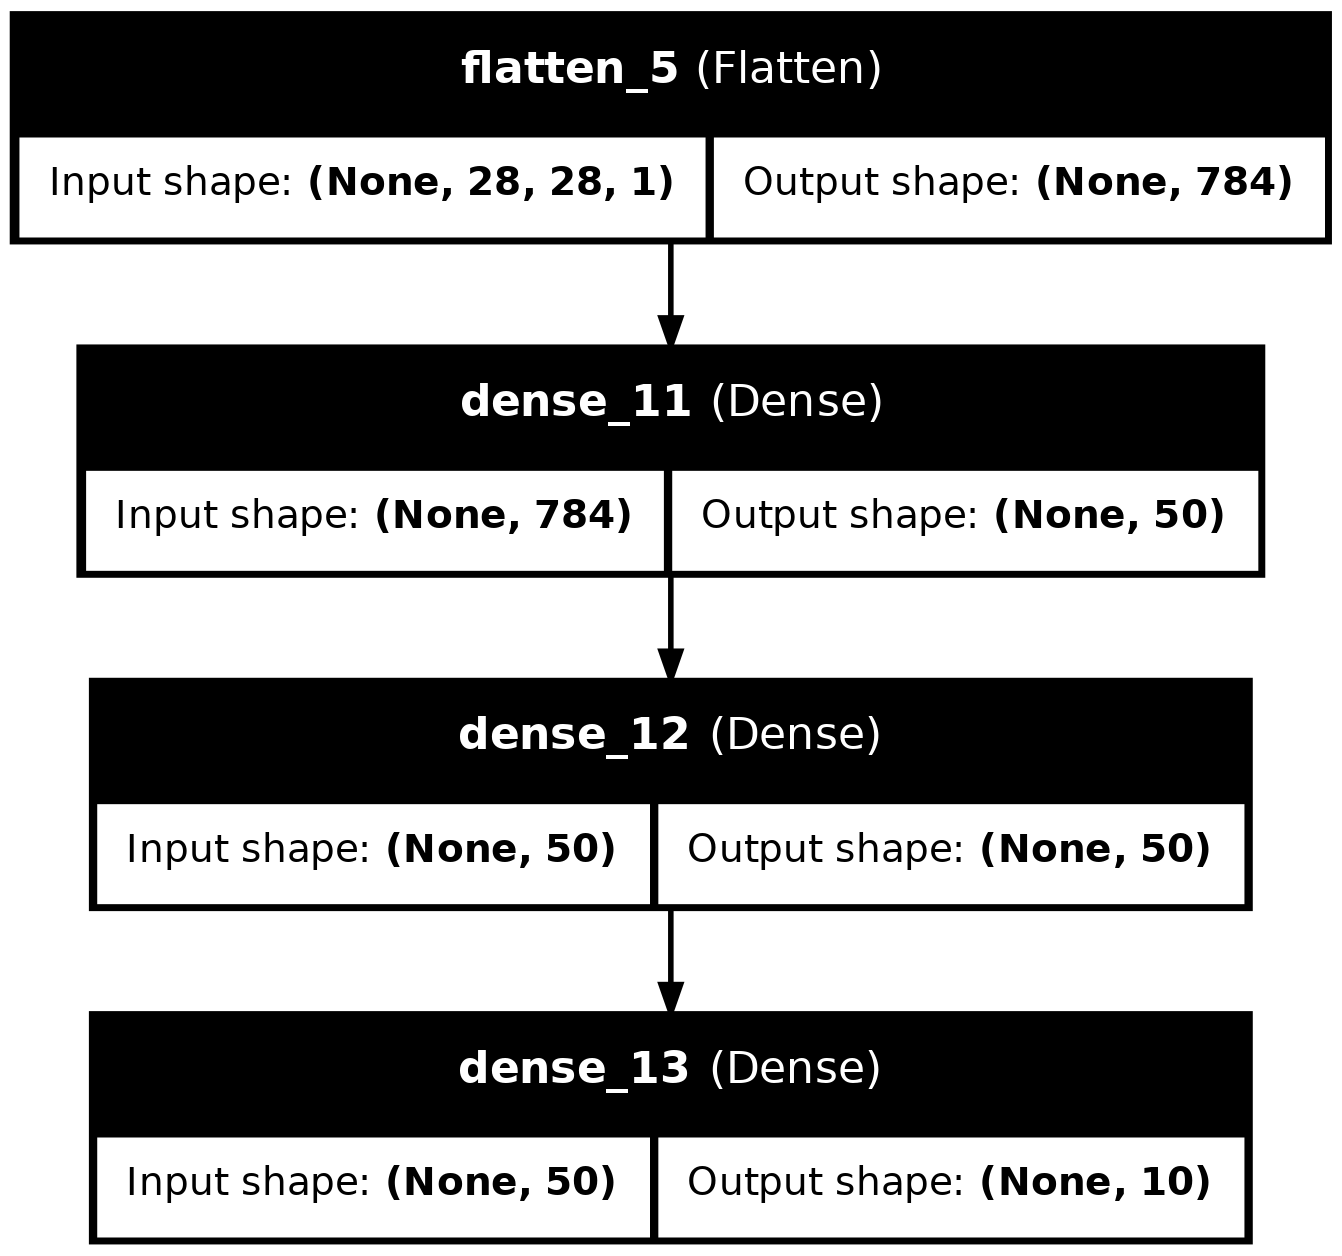

In [72]:
# 4.3 Visualizamos nuestro modelo con las conexiones
from keras.utils import plot_model
from keras.models import Sequential
from keras.layers import Dense
from PIL import Image

# Visualizar el modelo
plot_model(modelo, to_file='modelo2.png', show_shapes=True, show_layer_names=True, rankdir='LR')

# Mostrar el modelo
img = Image.open('modelo.png')
img.show()


# 5. Compilamos el Modelo

In [111]:
# 5.1 Compilamos el modelo
modelo.compile(
        optimizer = "adam",  # Definimos el potimizaador con adam para no ajustar la taza de aprendizaje
        loss = tf.keras.losses.SparseCategoricalCrossentropy(), # Definimos la perdida , de forma distinta ya que stamos clasificando y no estamos haciendo una regresion
        metrics = ["accuracy"] # con este accuracy nos dice cuando entrena no dice la exactitud del modelo
)

# 6. Realizamos preprocesamiento adicional

#- Realizamos optimizaciones para que no se acabe la memoria, en este tenemos 70K registros, eso significa hacer algunas optimizaciones para que funcione de manera eficaz y no se tarde tanto o se le acabe la memoria, POr lo tanto  definimos el tamano de LOTES , haciendo mas eficiente


In [112]:
# 6.1 Definimos el tamanio de LOTE
TAMANIO_LOTE = 32 # analizara de 32 en 32 registros
datos_entrenamiento = datos_entrenamiento.repeat().shuffle(60000).batch(TAMANIO_LOTE)
datos_pruebas = datos_pruebas.batch(TAMANIO_LOTE)

# 7. Realizamos el entrenamiento con 1 Capa Oculta y con 2 capas ocultas con 50 neuronas c/u y con RELU

In [113]:
# 7.1 Realizamos el entrenamiento con 1 Capa Oculta
import math

entrenamiento = modelo.fit(
    datos_entrenamiento,
    epochs=10,
    steps_per_epoch = math.ceil(60000/TAMANIO_LOTE)
)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8397 - loss: 0.5427
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9558 - loss: 0.1481
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9688 - loss: 0.1039
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9731 - loss: 0.0872
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9766 - loss: 0.0758
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9807 - loss: 0.0631
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9815 - loss: 0.0560
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9861 - loss: 0.0430
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9867 - loss: 0.0423
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9867 - loss: 0.0394


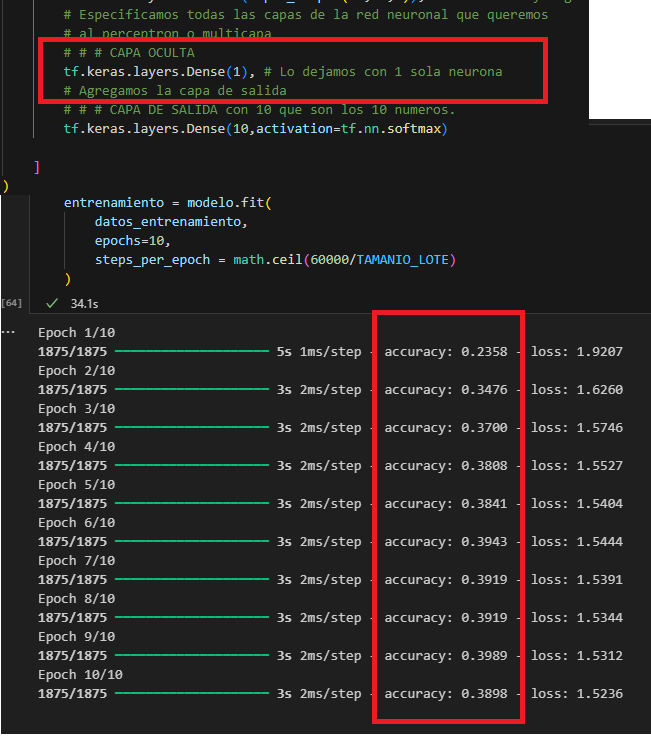

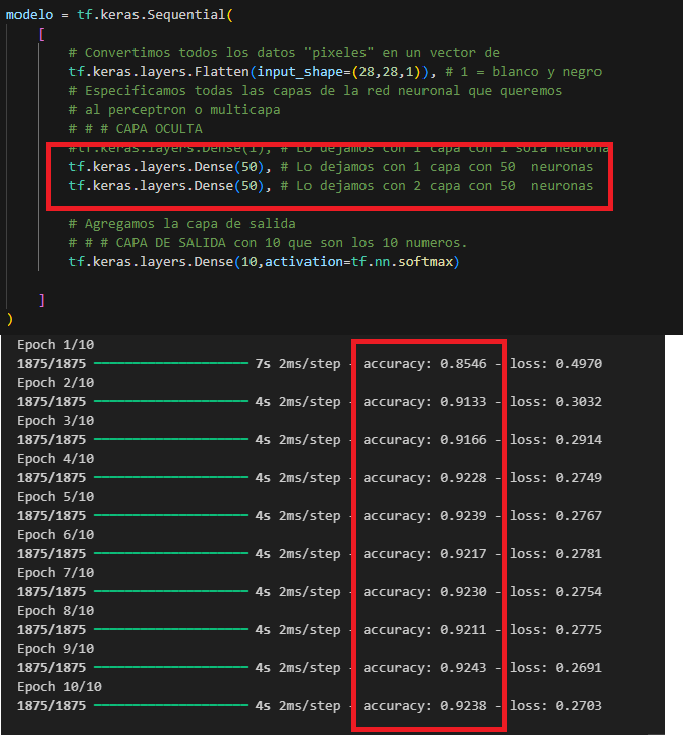

In [105]:
# Mostrar el modelo con 1 capa oculta con 1 neurona cada una, vemos que la presicion llega hasta el 39% de presicion
# Mostrar el modelo con 2 capa ocultas con 50 neuronas cada una, vemos que la presicion llega hasta el 92% de presicion

# Vemos que las neuronas de las 2 capas ocultas no tienen funcion de activacion es decir son lineales
# si queremos que se ajusten mejor , definimos una funcion de activamos.
# agregmos la funcion RELU

img = Image.open('1Dense.png')
img.show()
img = Image.open('2Dense-50.png')

img.show()

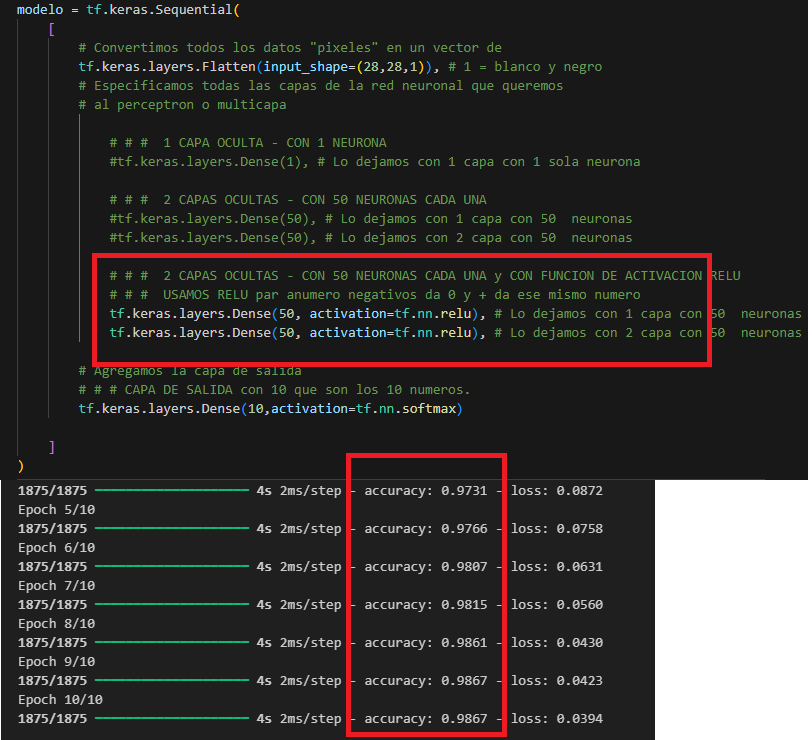

In [116]:
# FINALMENTE VEMOS LA RED CON RELU y VEMOS QUE LLEGO HASTA UN 98% de exactitud
img = Image.open('2Dense-50-W-RELU.png')
img.show()

# 8. Validamos las predicciones y su clasificacion

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


2024-06-01 17:25:36.477574: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2024-06-01 17:25:36.477803: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2024-06-01 17:25:36.591140: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence

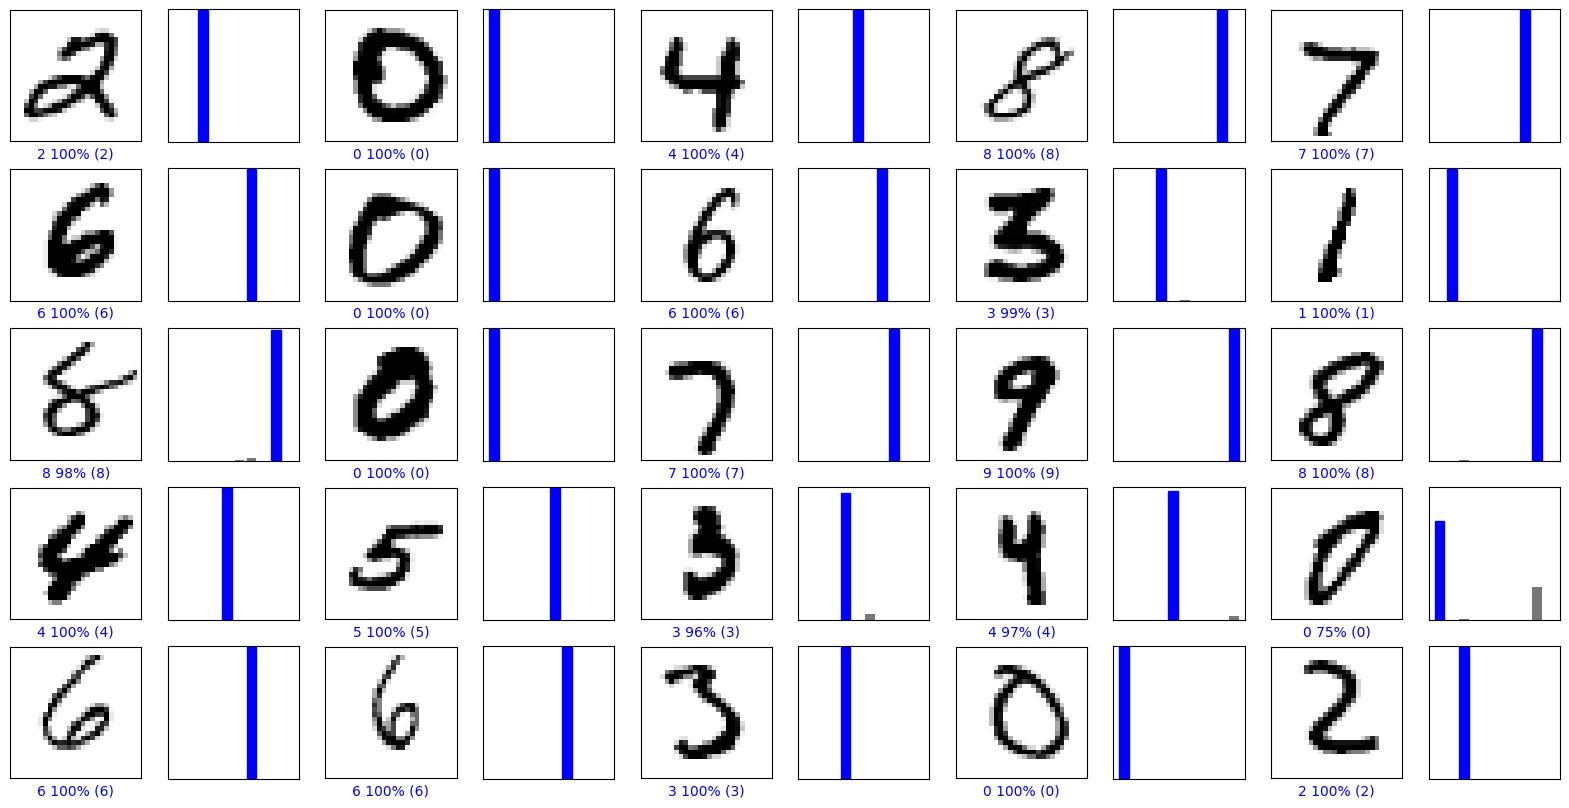

In [117]:
#Pintar una cuadricula con varias predicciones, y marcar si fue correcta (azul) o incorrecta (roja)
import numpy as np

for imagenes_prueba, etiquetas_prueba in datos_pruebas.take(1):
  imagenes_prueba = imagenes_prueba.numpy()
  etiquetas_prueba = etiquetas_prueba.numpy()
  predicciones = modelo.predict(imagenes_prueba)
  
def graficar_imagen(i, arr_predicciones, etiquetas_reales, imagenes):
  arr_predicciones, etiqueta_real, img = arr_predicciones[i], etiquetas_reales[i], imagenes[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])
  
  plt.imshow(img[...,0], cmap=plt.cm.binary)

  etiqueta_prediccion = np.argmax(arr_predicciones)
  if etiqueta_prediccion == etiqueta_real:
    color = 'blue'
  else:
    color = 'red'
  
  plt.xlabel("{} {:2.0f}% ({})".format(nombres_clases[etiqueta_prediccion],
                                100*np.max(arr_predicciones),
                                nombres_clases[etiqueta_real]),
                                color=color)
  
def graficar_valor_arreglo(i, arr_predicciones, etiqueta_real):
  arr_predicciones, etiqueta_real = arr_predicciones[i], etiqueta_real[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])
  grafica = plt.bar(range(10), arr_predicciones, color="#777777")
  plt.ylim([0, 1]) 
  etiqueta_prediccion = np.argmax(arr_predicciones)
  
  grafica[etiqueta_prediccion].set_color('red')
  grafica[etiqueta_real].set_color('blue')
  
filas = 5
columnas = 5
num_imagenes = filas*columnas
plt.figure(figsize=(2*2*columnas, 2*filas))
for i in range(num_imagenes):
  plt.subplot(filas, 2*columnas, 2*i+1)
  graficar_imagen(i, predicciones, etiquetas_prueba, imagenes_prueba)
  plt.subplot(filas, 2*columnas, 2*i+2)
  graficar_valor_arreglo(i, predicciones, etiquetas_prueba)